# SETP 1 : IMPORT EACH NECESSARY LIBRARIES

In [2]:
import numpy as np   # for array manipulation
import pandas as pd  # for data manipulation and datasets
from sklearn.model_selection import train_test_split  # splits datasets into TRAINING AND TESTING datasets
from sklearn.linear_model import LinearRegression   # used to create and train linear regression model
from sklearn.metrics import mean_squared_error,r2_score,mean_absolute_error  # evaluate regression models 
from sklearn.preprocessing import StandardScaler,PolynomialFeatures # feature scaling and polynomial feature transformation
from sklearn.pipeline import make_pipeline #pipeline of transformations and a final model
import matplotlib.pyplot as plt  # used for plotting the graphs


IMPORTED


# STEP 2: LOADING THE DATASETS

In [5]:
dataset=pd.read_csv("Salary_Data.csv")
print(dataset.head())

   YearsExperience   Salary
0              1.1  39343.0
1              1.3  46205.0
2              1.5  37731.0
3              2.0  43525.0
4              2.2  39891.0


# STEP 3: FIXING MISSING VALUE IF ANY

In [7]:
dataset.fillna(dataset.mean(),inplace=True)    

# STEP 4: Separate features (independent variables) and target (dependent variable)

In [13]:
X=dataset.iloc[:,:-1].values
Y=dataset.iloc[:,-1].values
print("x-axis (Experience Year)")
print((X))
print("================================================")
print("y-axis (Salary)")
print(Y)

x-axis (Experience Year)
[[ 1.1]
 [ 1.3]
 [ 1.5]
 [ 2. ]
 [ 2.2]
 [ 2.9]
 [ 3. ]
 [ 3.2]
 [ 3.2]
 [ 3.7]
 [ 3.9]
 [ 4. ]
 [ 4. ]
 [ 4.1]
 [ 4.5]
 [ 4.9]
 [ 5.1]
 [ 5.3]
 [ 5.9]
 [ 6. ]
 [ 6.8]
 [ 7.1]
 [ 7.9]
 [ 8.2]
 [ 8.7]
 [ 9. ]
 [ 9.5]
 [ 9.6]
 [10.3]
 [10.5]]
y-axis (Salary)
[ 39343.  46205.  37731.  43525.  39891.  56642.  60150.  54445.  64445.
  57189.  63218.  55794.  56957.  57081.  61111.  67938.  66029.  83088.
  81363.  93940.  91738.  98273. 101302. 113812. 109431. 105582. 116969.
 112635. 122391. 121872.]


# STEP 5:  Split the Data into Training and Testing Sets

In [32]:
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=1/5,random_state=2)
print("X TRAINING DATA",X_train)
print("====================================")
print("X TESTING DATA",X_test)
print("====================================")

print("Y TRAINING DATA",Y_train)
print("====================================")
print("Y TESTING DATA",Y_test)
print("====================================")

X TRAINING DATA [[ 8.2]
 [ 3. ]
 [ 2. ]
 [ 6.8]
 [ 2.9]
 [ 9.6]
 [ 4. ]
 [ 2.2]
 [ 3.9]
 [ 5.1]
 [10.3]
 [ 9. ]
 [ 5.3]
 [ 1.5]
 [ 3.2]
 [ 9.5]
 [ 8.7]
 [ 5.9]
 [ 4. ]
 [ 7.9]
 [10.5]
 [ 4.1]
 [ 4.9]
 [ 3.2]]
X TESTING DATA [[1.3]
 [1.1]
 [4.5]
 [3.7]
 [7.1]
 [6. ]]
Y TRAINING DATA [113812.  60150.  43525.  91738.  56642. 112635.  56957.  39891.  63218.
  66029. 122391. 105582.  83088.  37731.  54445. 116969. 109431.  81363.
  55794. 101302. 121872.  57081.  67938.  64445.]
Y TESTING DATA [46205. 39343. 61111. 57189. 98273. 93940.]


# STEP 6:  Initialize the Linear Regression Model

In [33]:
regressor=LinearRegression()

# STEP 7: Train the Model

In [35]:
regressor.fit(X_train,Y_train)  # Draws a best fit line

LinearRegression()

# STEP 8:  Make Predictions

In [36]:
Y_pred=regressor.predict(X_test) 
print("X_TEST DATA",X_test)
print("==============================")
print("Predicted Data",Y_pred)
print("==============================")
print("Actual Data",Y_test)


X_TEST DATA [[1.3]
 [1.1]
 [4.5]
 [3.7]
 [7.1]
 [6. ]]
Predicted Data [36833.63210301 34919.71472592 67456.3101364  59800.64062805
 92337.23603852 81810.69046455]
Actual Data [46205. 39343. 61111. 57189. 98273. 93940.]


# STEP 9: Evaluate the Model

### 9.1: Mean Squared Error (MSE)

In [38]:
mse=mean_squared_error(Y_pred,Y_test)
print("Mean Squared Error",mse)

## ROOTING MEAN SQUARED 
rmse=np.sqrt(mse)
print("Root Mean Squared Error",rmse)


Mean Squared Error 56137509.9978255
Root Mean Squared Error 7492.496913434499


### 9.2 : Calculate Mean Absolute Error (MAE)

In [39]:
mae=mean_absolute_error(Y_pred,Y_test)
print("Mean absolute Error",mae)

Mean Squared Error 6802.779572073898


### 9.3: Calculate R-squared

In [40]:
r2=r2_score(Y_pred,Y_test)
print("R squared Score",r2)

R squared Score 0.8758881970900053


# STEP 10: Visualize the Results

### Plotting actual vs predicted values

Text(0.5, 1.0, 'Actual vs Predicted')

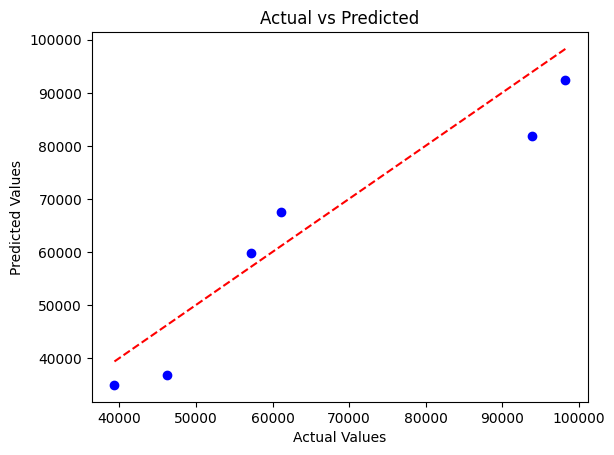

In [43]:
plt.scatter(Y_test, Y_pred, color='blue')
plt.plot([Y_test.min(), Y_test.max()], [Y_test.min(), Y_test.max()], color='red', linestyle='--')
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted")